In [2]:
# Import Libraries

import matplotlib.pyplot as plt
import numpy as np
import cv2

# Import from data.py
from src.data import (
    get_image_mask_pairs,
    split_dataset,
    load_image,
    load_ground_truth,
    degrade_image,
    apply_mean_filter,
    apply_gaussian_filter,
    apply_median_filter,
    IMAGES_OUTPUT,
    MASKS_OUTPUT
)

In [3]:
# Prepare Dataset

pairs = get_image_mask_pairs()

train_pairs, test_pairs = split_dataset(pairs)

# Select one sample
image_path, mask_path = train_pairs[0]

# Load original image and mask
image = load_image(image_path)
mask = load_ground_truth(mask_path)

# Generate degraded images
noise_types = ["gaussian", "salt_pepper", "speckle", "poisson", "blur"]

noisy_images = {
    noise: degrade_image(image, method=noise, seed=42)
    for noise in noise_types
}

# Apply restoration filters to Gaussian noisy image
mean_image = apply_mean_filter(noisy_images["gaussian"])
gaussian_image = apply_gaussian_filter(noisy_images["gaussian"])
median_image = apply_median_filter(noisy_images["gaussian"])

# Store restoration results
restored_images = {
    "Mean Filter": mean_image,
    "Gaussian Filter": gaussian_image,
    "Median Filter": median_image
}

print("Dataset:", len(pairs))
print("Training:", len(train_pairs))
print("Testing:", len(test_pairs))
print("Image Shape:", image.shape)
print("Mask Shape:", mask.shape)

Dataset: 1000
Training: 700
Testing: 300
Image Shape: (512, 512, 3)
Mask Shape: (512, 512)


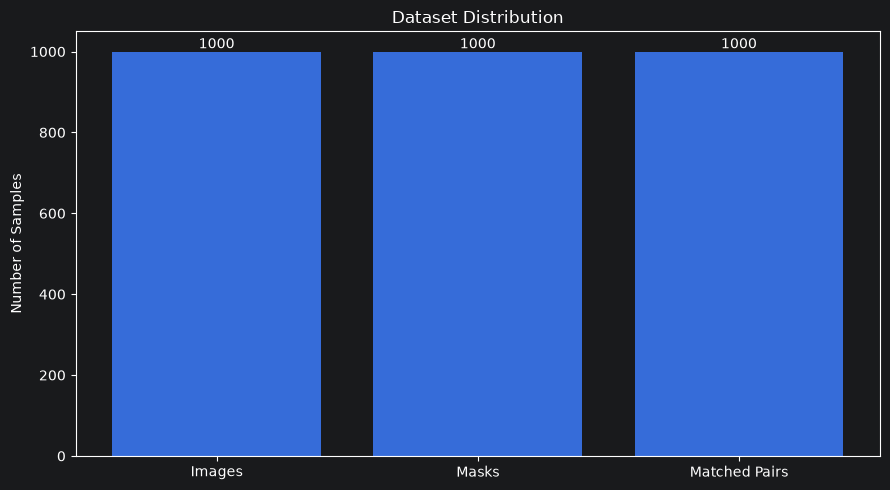

In [4]:
# Dataset Distribution Visualization

labels = ["Images", "Masks", "Matched Pairs"]

values = [
    len(list(IMAGES_OUTPUT.glob("*.png"))),
    len(list(MASKS_OUTPUT.glob("*.png"))),
    len(pairs)
]

plt.figure(figsize=(9, 5))

bars = plt.bar(labels, values)

plt.title("Dataset Distribution")
plt.ylabel("Number of Samples")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        int(bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

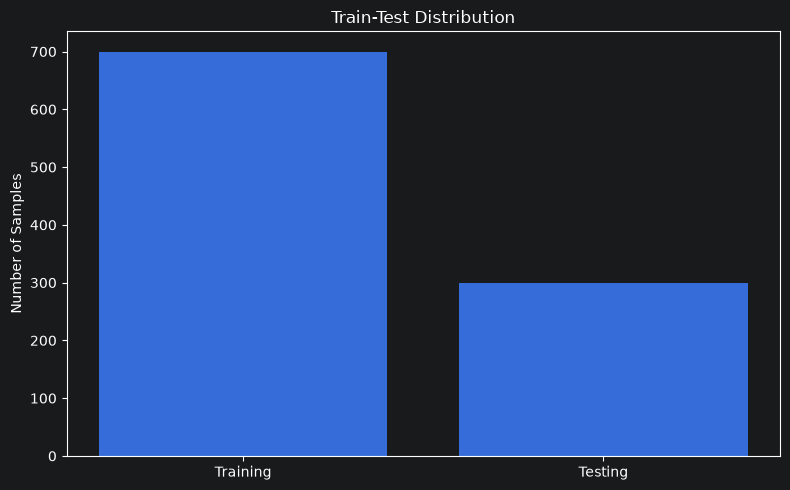

In [5]:
# Train-Test Distribution Visualization

plt.figure(figsize=(8, 5))

plt.bar(
    ["Training", "Testing"],
    [len(train_pairs), len(test_pairs)]
)

plt.title("Train-Test Distribution")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.show()

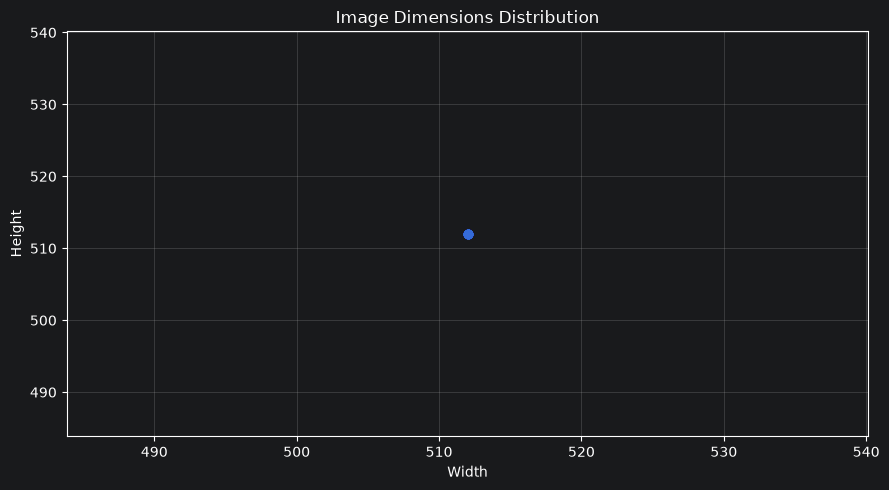

In [6]:
# Image Dimensions Visualization

dimensions = [
    load_image(image_path).shape[:2]
    for image_path, mask_path in pairs
]

heights = [d[0] for d in dimensions]
widths = [d[1] for d in dimensions]

plt.figure(figsize=(9, 5))

plt.scatter(widths, heights, alpha=0.5)

plt.title("Image Dimensions Distribution")
plt.xlabel("Width")
plt.ylabel("Height")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

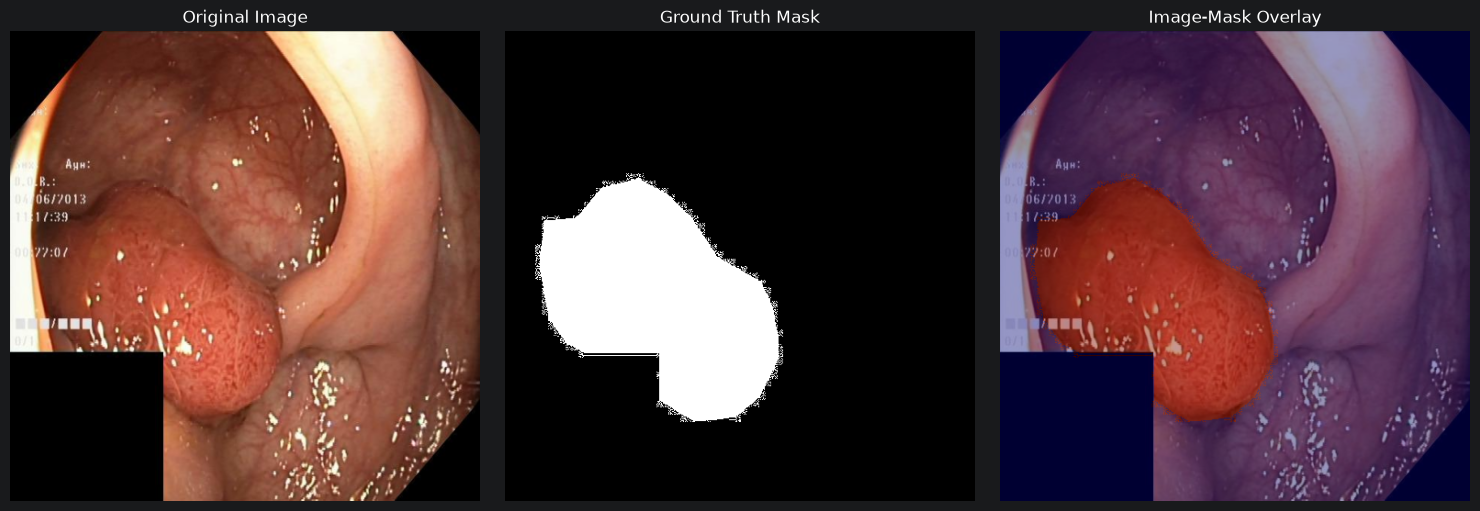

In [7]:
# Image and Mask Visualization

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(mask, cmap="jet", alpha=0.4)
plt.title("Image-Mask Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

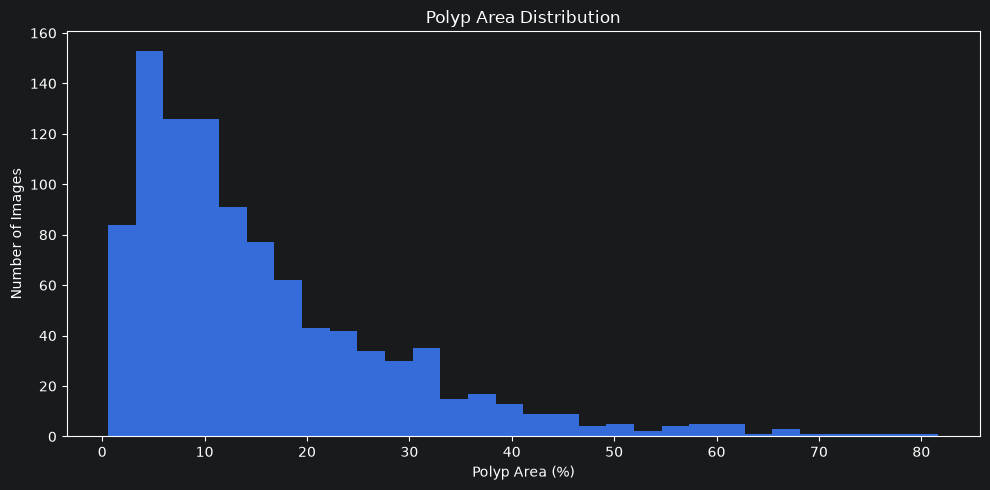

In [8]:
# Polyp Area Distribution

polyp_percentages = []

for image_path, mask_path in pairs:

    current_mask = load_ground_truth(mask_path)

    polyp_area = np.sum(current_mask > 0)

    total_area = current_mask.size

    percentage = (polyp_area / total_area) * 100

    polyp_percentages.append(percentage)

plt.figure(figsize=(10, 5))

plt.hist(polyp_percentages, bins=30)

plt.title("Polyp Area Distribution")
plt.xlabel("Polyp Area (%)")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

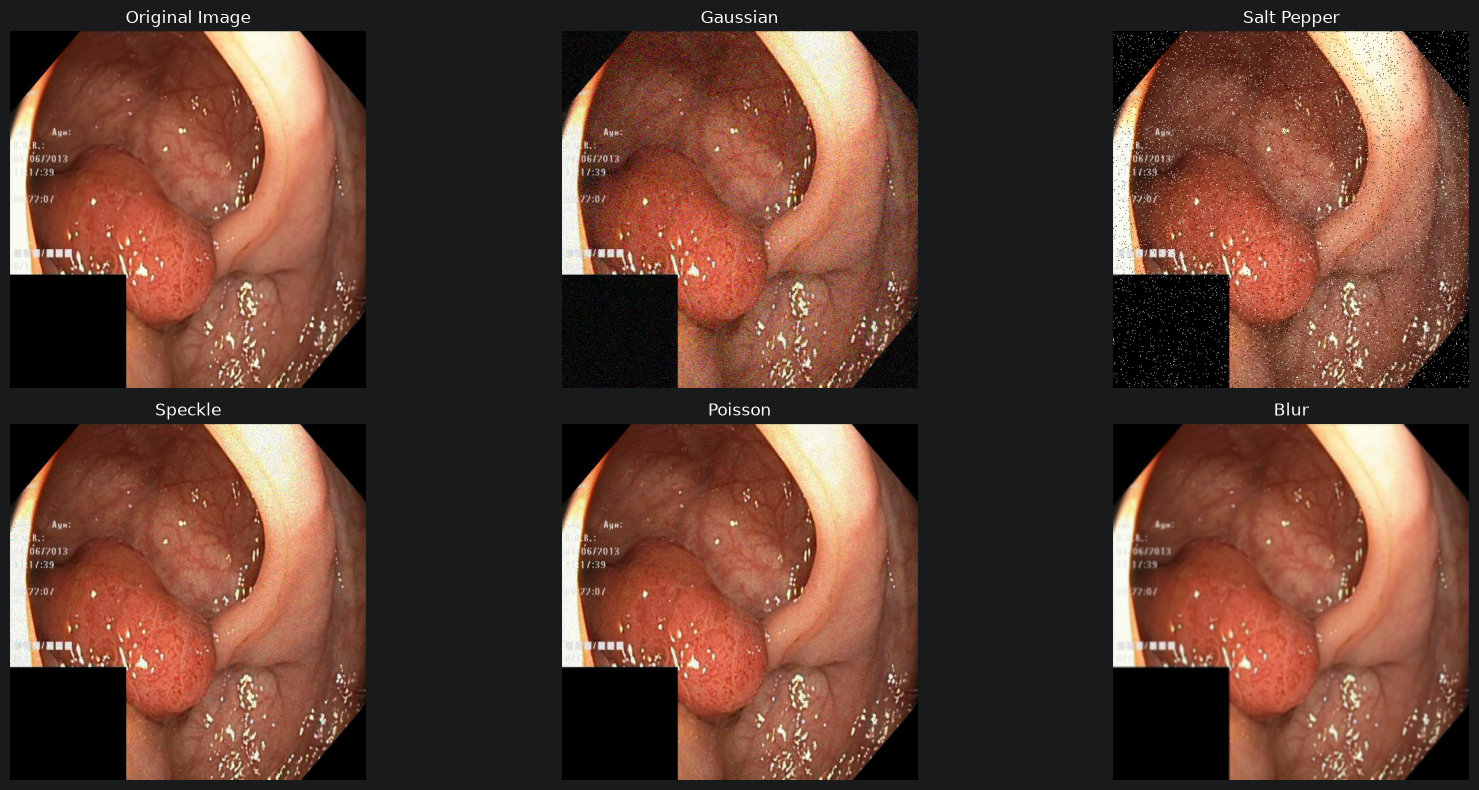

In [9]:
# Noise Types Comparison

plt.figure(figsize=(18, 8))

plt.subplot(2, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

for i, (name, noisy) in enumerate(noisy_images.items()):

    plt.subplot(2, 3, i + 2)

    plt.imshow(noisy)
    plt.title(name.replace("_", " ").title())
    plt.axis("off")

plt.tight_layout()
plt.show()

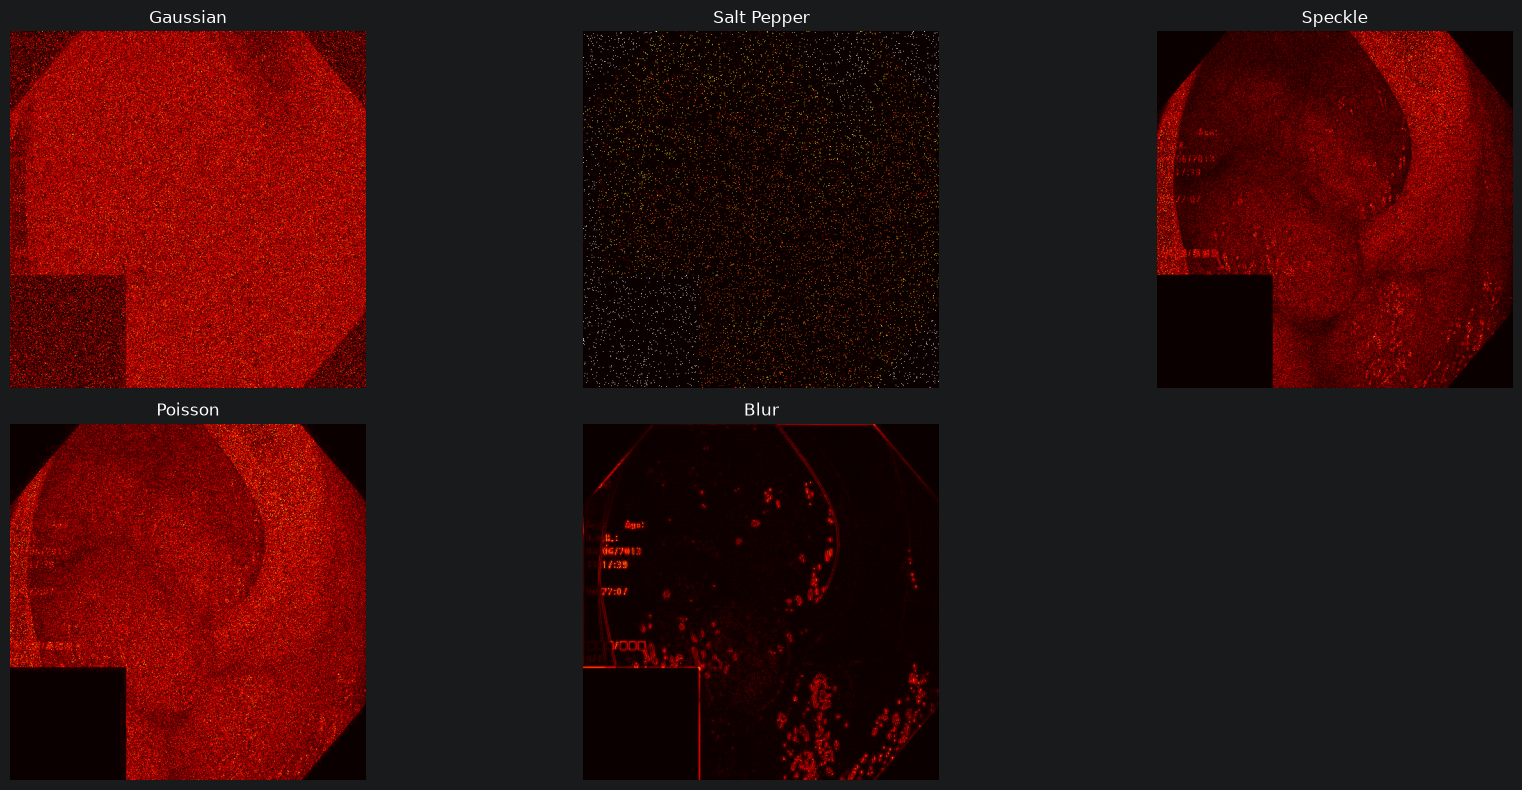

In [10]:
# Noise Difference Visualization

plt.figure(figsize=(18, 8))

for i, (name, noisy) in enumerate(noisy_images.items()):

    difference = cv2.absdiff(image, noisy)

    difference = cv2.cvtColor(
        difference,
        cv2.COLOR_RGB2GRAY
    )

    plt.subplot(2, 3, i + 1)

    plt.imshow(difference, cmap="hot")

    plt.title(name.replace("_", " ").title())
    plt.axis("off")

plt.tight_layout()
plt.show()

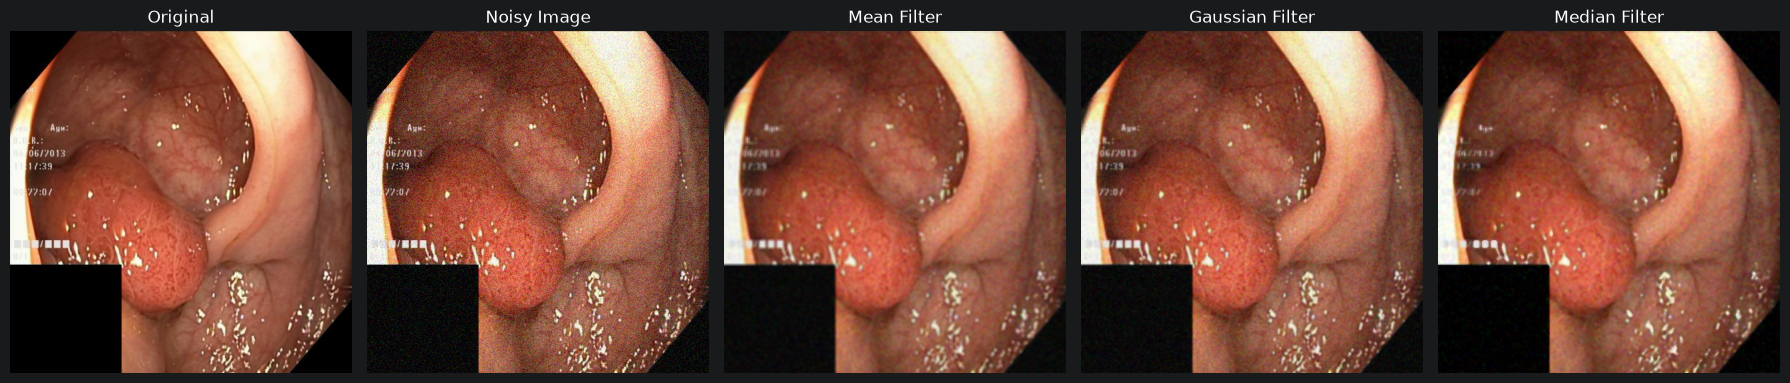

In [11]:
# Restoration Filters Comparison

plt.figure(figsize=(18, 6))

plt.subplot(1, 5, 1)
plt.imshow(image)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 5, 2)
plt.imshow(noisy_images["gaussian"])
plt.title("Noisy Image")
plt.axis("off")

for i, (name, restored) in enumerate(restored_images.items()):

    plt.subplot(1, 5, i + 3)

    plt.imshow(restored)
    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()

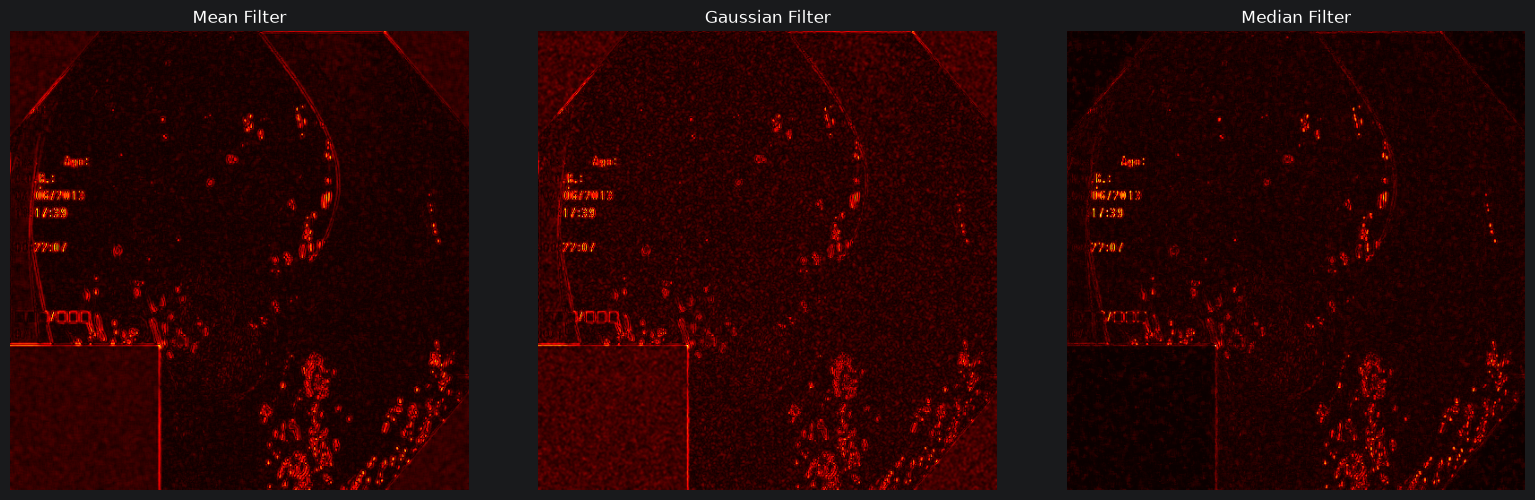

In [12]:
# Restoration Difference Maps

plt.figure(figsize=(16, 5))

for i, (name, restored) in enumerate(restored_images.items()):

    difference = cv2.absdiff(image, restored)

    difference = cv2.cvtColor(
        difference,
        cv2.COLOR_RGB2GRAY
    )

    plt.subplot(1, 3, i + 1)

    plt.imshow(difference, cmap="hot")

    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()

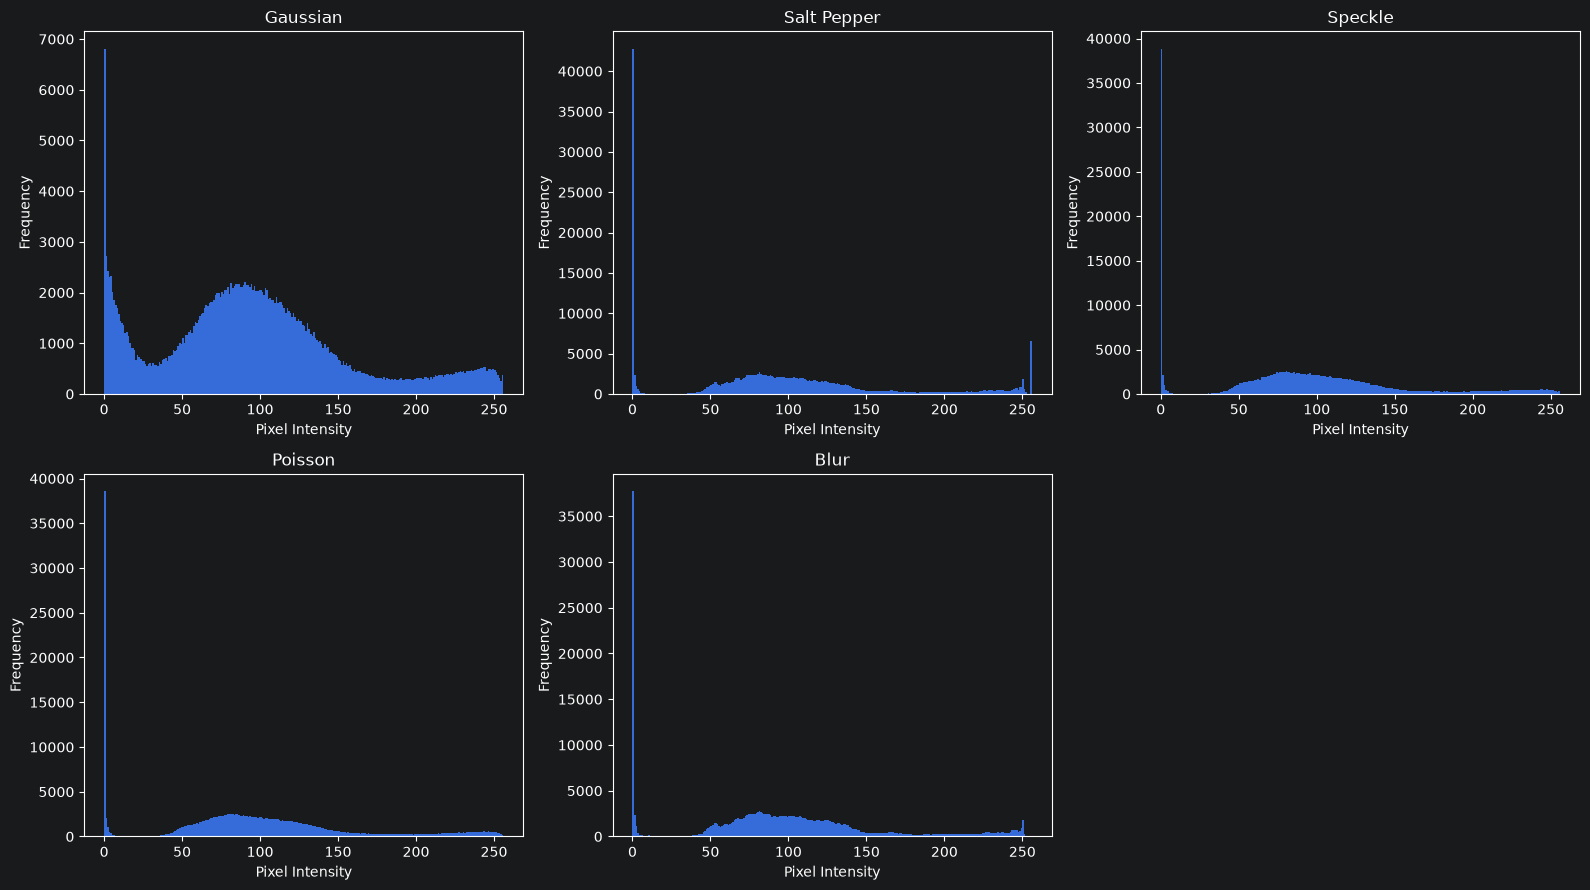

In [13]:
# Noise Histogram Comparison

plt.figure(figsize=(16, 9))

for i, (name, current_image) in enumerate(noisy_images.items()):

    gray = cv2.cvtColor(
        current_image,
        cv2.COLOR_RGB2GRAY
    )

    plt.subplot(2, 3, i + 1)

    plt.hist(
        gray.ravel(),
        bins=256,
        range=(0, 256)
    )

    plt.title(name.replace("_", " ").title())
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

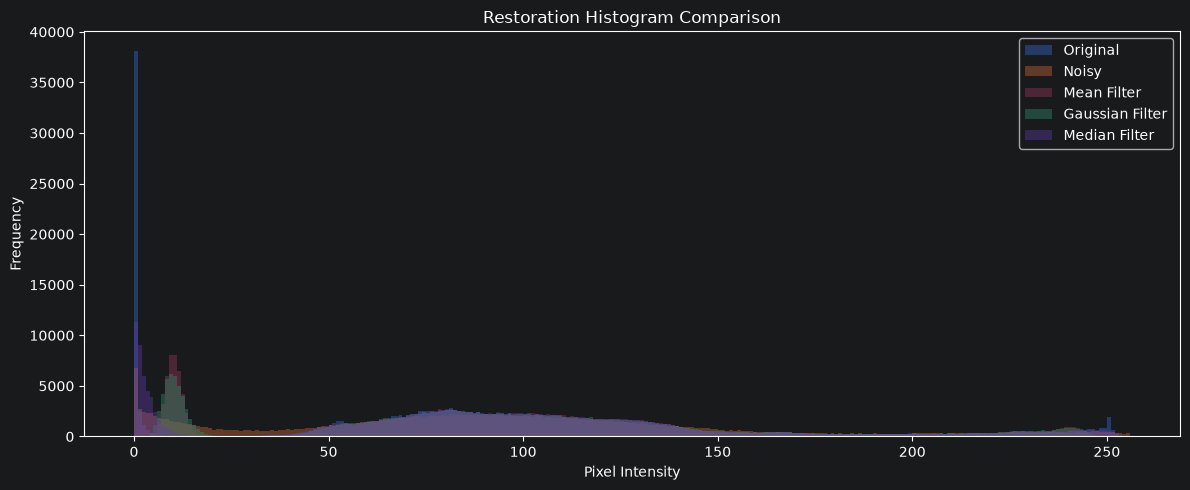

In [14]:
# Restoration Histogram Comparison

plt.figure(figsize=(12, 5))

comparison_images = {
    "Original": image,
    "Noisy": noisy_images["gaussian"],
    **restored_images
}

for name, current_image in comparison_images.items():

    gray = cv2.cvtColor(
        current_image,
        cv2.COLOR_RGB2GRAY
    )

    plt.hist(
        gray.ravel(),
        bins=256,
        range=(0, 256),
        alpha=0.4,
        label=name
    )

plt.title("Restoration Histogram Comparison")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.legend()
plt.tight_layout()
plt.show()

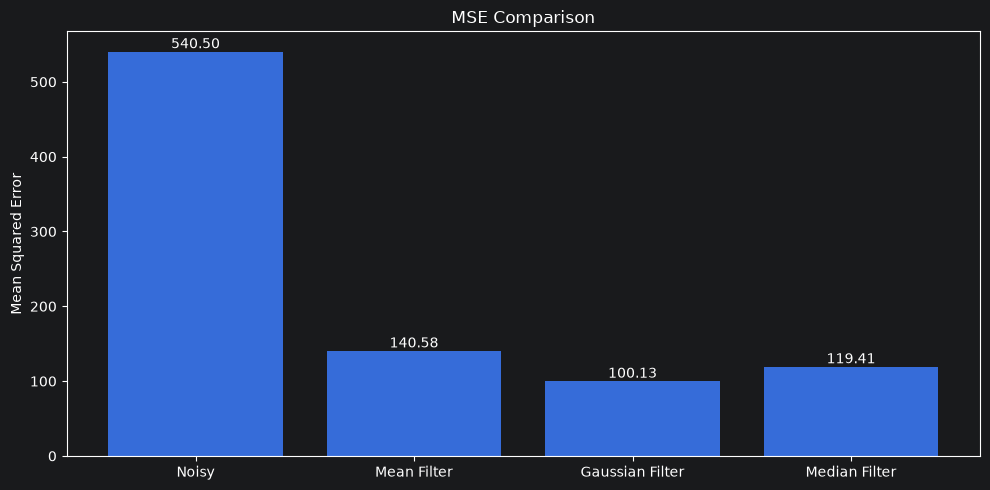

In [15]:
# MSE Comparison

original_float = image.astype(np.float32)

mse_results = {}

for name, current_image in {
    "Noisy": noisy_images["gaussian"],
    **restored_images
}.items():

    difference = original_float - current_image.astype(np.float32)

    mse_results[name] = np.mean(difference ** 2)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    mse_results.keys(),
    mse_results.values()
)

plt.title("MSE Comparison")
plt.ylabel("Mean Squared Error")

for bar in bars:

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

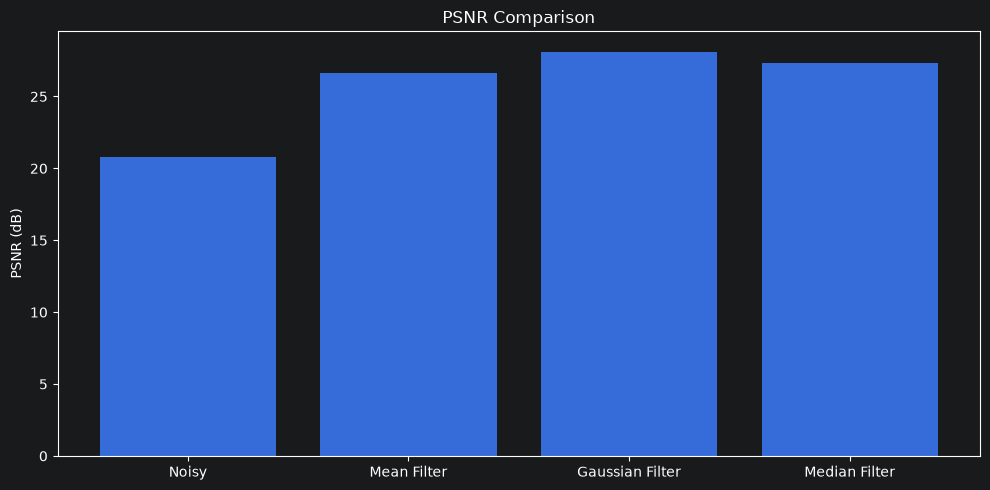

In [16]:
# PSNR Comparison

psnr_results = {}

for name, current_image in {
    "Noisy": noisy_images["gaussian"],
    **restored_images
}.items():

    mse = mse_results[name]

    if mse == 0:
        psnr_results[name] = float("inf")
    else:
        psnr_results[name] = 10 * np.log10(255 ** 2 / mse)

plt.figure(figsize=(10, 5))

plt.bar(
    psnr_results.keys(),
    psnr_results.values()
)

plt.title("PSNR Comparison")
plt.ylabel("PSNR (dB)")

plt.tight_layout()
plt.show()